> **Redacted copy for aaronsuu.github.io.** *Dataset not included: it was provided for course use only and contains sensitive responses. Notebook outputs that showed raw data have been removed.* Code and charts are unchanged; the notebook will not run without the data.

# Homework 2 - Aaron Su

## Install non-standard Libraries


In [151]:
#Run this cell only once to install the libraries that do not come with Python
#or Colab by default
!pip install contractions nltk wordcloud ftfy language-tool-python
!python -m spacy download en_core_web_sm

# Import Modules, Functions, and other Code

In [152]:
#This cell imports all necessary modules, functions, and other "things" necessary to run all the cells in this notebook file
#Some repetiation occurs and is for explanatory purposes only
#In a more typical notebook file, importing would be done on a cell-by-cell basis

#Modules required for creating dataframes and handling arrays
import pandas as pd #enables use of pandas libraries with alias pd
import numpy as np #enables use of numpy libraries with alias np
import string

#Module required to expand contractions
import contractions

#Module required for removing stopwords
import nltk
from nltk.corpus import stopwords
nltk.download('stopwords')

#Modules and functiosn needed for lemmatizing
nltk.download('punkt')        # Required for tokenizing text
nltk.download('wordnet')      # The lexical database used for lemmatization
nltk.download('averaged_perceptron_tagger') # Required for POS tagging
nltk.download('punkt_tab')
nltk.download('averaged_perceptron_tagger_eng')
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem.wordnet import WordNetLemmatizer
from nltk.corpus import wordnet

#Module required for plotting results
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from wordcloud import WordCloud, STOPWORDS
from collections import Counter
from nltk.corpus import stopwords
from nltk.util import ngrams
import nltk
import re


In [153]:
#Load data into a dataframe
#Before loading data, fully clean the data and
#verify that it has been cleaned and de-identified appopriately
#Before running this cell, ensure that data file (.xlsx) is copied into the "content folder" in the CoLab environment

#If running this notebook file in CoLab --
#Navigate to the file folder icon on the left sidebar
#Select the file folder preceding "...", then select the content folder

# Load dataset into a dataframe
# A dataframe is a two-dimenaional, heterogeneous data structure that acts much like a spreadsheet
# By default, Python assumes that the first row of an .xlsx or .csv file contains labels for each column
# By default, Python assigns an indext (number) to each row as a lable for that row (not including the first row)
# It is also possible to explicitly assign a column of data as the "row labels" for that dataframe
# Dataframes also allow data to be  heterogenous, meaning different columns can contain strings/text, floating point numbers, integers, etc.

#Load the Peer Support Data into a datframe
file_path = 'content/Reflections_AffectiveState.xlsx'
data = pd.read_excel(file_path)

#Copy the raw peer support data to another dataframe
#the new dataframe will contain only the raw data
#this is not a required step, but it does allow for retaining only the data of interest for this notebook
data_reduced = data[['OriginalResponse']].copy()

#Print the new dataframe to verify that it has been copied correctly
print (data_reduced)


# Data Cleaning

In [154]:
#Fix Character Encoding (mojibake)
#Moved to the front of the Data Cleaning section: every step below reads the
#text, so the text has to be readable first.  Left at the end, the duplicate
#key did not match across rows whose apostrophes were damaged differently, and
#spaCy read the leftovers as named entities (TM, I´m, doesn´t).
#Some responses contain UTF-8 bytes that were decoded as Mac Roman upstream
#e.g. "‚Ñ¢" should be "™"  --  these garbage tokens confuse spaCy's NER
import ftfy, html, re, unicodedata

def fix_encoding(text):
    #Round-trip back through Mac Roman and re-decode as UTF-8.
    #errors='strict' on the whole string gave up on rows that were only
    #partly damaged, so the loop re-tries and ftfy mops up the rest.
    for _ in range(3):                      #a few rows were damaged twice
        try:
            candidate = text.encode('mac_roman').decode('utf-8')
        except (UnicodeEncodeError, UnicodeDecodeError):
            break                           #already clean, leave it alone
        if candidate == text:
            break
        text = candidate
    return ftfy.fix_text(text)

#Smart quotes and dashes are folded to ASCII so that expanding contractions in
#preprocessing recognises "don’t" as "don't"
PUNCT_MAP = {'‘': "'", '’': "'", '‚': "'", '“': '"',
             '”': '"', '„': '"', '«': '"', '»': '"',
             '–': '-', '—': '-', '…': '...', '´': "'"}

def normalize_text(text):
    for bad, good in PUNCT_MAP.items():
        text = text.replace(bad, good)
    #Drop control and stand-alone symbol characters (zero-width spaces, emoji,
    #trademark and degree signs).  NFKC alone is not enough here: it expands
    #"™" into the literal word "TM", which spaCy then reports as an ORG.
    text = ''.join(c for c in text if unicodedata.category(c) not in
                   ('Cc', 'Cf', 'Cn', 'Co', 'Cs', 'So', 'Sk', 'Sm'))
    text = unicodedata.normalize('NFKC', text)
    return re.sub(r'\s+', ' ', text).strip()

data_reduced['Encoded'] = (data_reduced['OriginalResponse'].fillna('').astype(str)
                           .apply(fix_encoding).apply(normalize_text))

#Print Repaired Data for Sanity Checking
print(f"Rows repaired: {(data_reduced['Encoded'] != data_reduced['OriginalResponse']).sum()}")
print(data_reduced['Encoded'])

In [155]:
#Remove URLs and HTML tags
#Reads the repaired column, and the result is carried forward by the cells
#below -- previously this wrote a column that nothing else ever read.
data_reduced['NoURLs'] = (data_reduced['Encoded']
                          .apply(html.unescape)                              #&amp; -> &
                          .str.replace(r'<.*?>', ' ', regex=True)            #HTML tags
                          .str.replace(r'http\S+|www\.\S+', ' ', regex=True) #URLs
                          .str.replace(r'(?<!\w)#(\w)', r'\1', regex=True)   #keep hashtag words
                          .str.replace(r'\s+', ' ', regex=True)
                          .str.strip())
print(data_reduced['NoURLs'])

In [156]:
#Duplicates
#Normalize first (strip whitespace, lower case) so near-duplicates collapse to exact duplicates
#Run after the encoding fix: before it, the four copies of "No regrets or
#grudges..." had differently damaged apostrophes and did not collapse
key = data_reduced['NoURLs'].str.lower().str.replace(r'[^a-z0-9]', '', regex=True)

#Print every row in a duplicate group before dropping
print(data_reduced.loc[key.duplicated(keep=False) & (key != ''), 'NoURLs'])

#Keep the first occurrence of each, drop the rest
data_reduced = data_reduced[~(key.duplicated() & (key != ''))].copy()
print(f"Duplicates dropped: {(key.duplicated() & (key != '')).sum()}")
print(f"Rows remaining: {len(data_reduced)}")

In [157]:
#Non-Responses
#Blank responses
print("Blank (NaN) responses:", data_reduced['OriginalResponse'].isna().sum())

#Responses whose text indicates a non-answer, plus cells that are blank after
#the encoding fix and cells padded out with dots ("TL Cleaning...............")
blank = data_reduced['NoURLs'].str.len() == 0
stated = data_reduced['NoURLs'].str.contains(
    r'^\s*(?:idk|n/?a|none|nothing(?: really)?|no comment|no ?response|null|nil)\s*[.!]?\s*$',
    case=False, na=False, regex=True)
padding = (data_reduced['NoURLs'].str.count(r'\.')
           / data_reduced['NoURLs'].str.len().clip(lower=1)) > 0.25

mask = blank | stated | padding
print(data_reduced.loc[mask, 'NoURLs'])

#Drop them, instead of only printing them as before
data_reduced = data_reduced[~mask].copy()
print(f"Non-responses dropped: {mask.sum()}")
print(f"Rows remaining: {len(data_reduced)}")

In [158]:
#Outliers
#Flag responses whose word count is far outside the mean (3 standard deviations)
#Printed but NOT dropped: reading them shows they are long, detailed
#first-person accounts, which are the most informative rows in the corpus
word_count = data_reduced['NoURLs'].str.split().str.len()
outliers = (word_count - word_count.mean()).abs() > 3 * word_count.std()

print(f"Mean word count: {word_count.mean():.1f}")
print(f"Outlying responses: {outliers.sum()}  (flagged, kept)")
print(data_reduced.loc[outliers, 'NoURLs'])

In [159]:
#Correct Spelling and Grammar Errors (contextual)
import language_tool_python

# This automatically downloads a local server jar file on first run
tool = language_tool_python.LanguageTool("en-US")

#Run on a sample rather than all 2231 rows: a full pass prints tens of
#thousands of messages, and the suggestions are not applied anyway.
#These are machine translations of social media posts, so the broken grammar
#(e.g. repeated words and unusual phrasing) is the affective
#signal being studied -- correcting it would delete the data.
sample = data_reduced['NoURLs'].sample(50, random_state=0)

for idx, text in sample.items():
    matches = tool.check(text)
    # Print out the contextual suggestions
    for match in matches[:3]:
        print(f"Row {idx}")
        print(f"Issue: {match.message}")
        print(f"Suggestions: {match.replacements}\n")

In [160]:
#De-Identifying Data
#Last cleaning step, because it reads the text that the cells above produced
import spacy
nlp = spacy.load("en_core_web_sm")

#spaCy proposes several hundred entities on this corpus and most are false
#positives that must NOT be removed -- the clinical terms and medication names
#are the subject matter.  Anything in KEEP is left in the text.
KEEP = {
        'xanax', 'effexor', 'prozac', 'zoloft', 'buspar', 'lamictal', 'prazosin',
        'lexapro', 'wellbutrin', 'mirtazapine', 'lorazepam', 'alprazolam',
        'covid', 'corona', 'asperger', 'aspergers', 'agoraphobia',}

#Square brackets are the standard convention for de-identified text
LABEL_TAGS = {'PERSON': '[individual name]',
              'GPE': '[location]', 'LOC': '[location]', 'FAC': '[location]'}

def de_identify(text):
    doc = nlp(text)
    #Replace from the end of the string backwards so the earlier character
    #offsets stay valid
    for ent in reversed(doc.ents):
        if ent.label_ in LABEL_TAGS and ent.text.lower().strip() not in KEEP:
            text = text[:ent.start_char] + LABEL_TAGS[ent.label_] + text[ent.end_char:]
    return text

data_reduced['DeIdentified'] = data_reduced['NoURLs'].apply(de_identify)

#Print the named entities that were replaced, for sanity checking
for idx, text in data_reduced['NoURLs'].items():
    for ent in nlp(text).ents:
        if ent.label_ in LABEL_TAGS and ent.text.lower().strip() not in KEEP:
            print(f"Row {idx} | {ent.text} | {ent.label_}")

In [161]:
#Place the cleaned reflections in a column labelled CleanedResponse
#and write it back to the Reflections_AffectiveState spreadsheet.
#Assigning by index leaves CleanedResponse blank for the rows that cleaning
#dropped, so every remaining row still lines up with its AssignedTheme.
data_reduced['CleanedResponse'] = data_reduced['DeIdentified']
data['CleanedResponse'] = data_reduced['CleanedResponse']
data.to_excel(file_path, index=False)

print(f"Rows in: {len(data)}   Rows cleaned: {data['CleanedResponse'].notna().sum()}")
print(f"CleanedResponse written to {file_path}")
print(data_reduced['CleanedResponse'])

# Data Segmentation

In [162]:
#Segment the cleaned data into its four themes
#In the lecture, segmentation groups the documents of a corpus into logical,
#related blocks once cleaning is done and before preprocessing.  Here the
#blocks are already labelled: every response has an AssignedTheme (Anxiety,
#Depression, Normal or Stress), so the corpus is grouped on that column.

#Bring AssignedTheme across from the full dataframe.  Pandas matches on the row
#index, so each cleaned response gets the theme of its own original row and the
#rows dropped during cleaning are simply left out.
data_reduced['AssignedTheme'] = data['AssignedTheme']

#The four themes, in a fixed order so every plot below uses the same layout
themes = sorted(data_reduced['AssignedTheme'].dropna().unique())

#Print the size of each segment for Sanity Checking
segment_sizes = pd.DataFrame({
    'Responses': data_reduced.groupby('AssignedTheme')['CleanedResponse'].count(),
    'Words': data_reduced.groupby('AssignedTheme')['CleanedResponse'].apply(
        lambda group: group.str.split().str.len().sum()),
})
segment_sizes['WordsPerResponse'] = (segment_sizes['Words'] / segment_sizes['Responses']).round(1)
print(segment_sizes)

# Data PreProcessing

In [163]:
#This step in data preprocessing removes blanks responses and replaces the
#CleanedResponse column with only the cells that contain text
#While keeping track of the index number so that the revised dataframe can be traced back to the original dataframe
#with only those responses that are not blank
#The input is CleanedResponse, the output of the Data Cleaning section --
#reading OriginalResponse here would throw away all of the cleaning above

#Remove NaNs (blank responses) and replace the dataframee with "new" data that has eliminated no responses (NaNs)
data_reduced = data_reduced.dropna(subset=['CleanedResponse']).copy()

#Print Filtered Data (with NaNs removed) for Sanity Checking
print (data_reduced['CleanedResponse'])

In [164]:
#Covert Text to Lower Case

#This step in data preparation and preprocessing converts all text to lower case
#To avoid any problems with case-senstitive processing and topic modelling in subsequent cells

#Convert all text to lower case
data_reduced['LowerCase'] = data_reduced['CleanedResponse'].str.lower()

#Print  Lower Case Data for Sanity Checking
print (data_reduced['LowerCase'])

In [165]:
#Expand Contractions
#This step expands Contractions (e.g. "don't" to "do not")

#Define function that expands contractions in a single string of text
def expand_contractions_text(text):
    if isinstance(text, str):
        # contractions.fix() handles the entire string/sentence
        expanded_text = contractions.fix(text)
        return expanded_text
    return text

#Apply the function to all of the texts in "LowerCase" column of the dataframe
data_reduced['ExpandContractions'] = data_reduced['LowerCase'].apply(expand_contractions_text)

#Print Expaneded Data for Sanity Checking
print (data_reduced['ExpandContractions'])

In [166]:
#Remove Punctuation

#De-identification wrote placeholders in square brackets -- [individual name],
#[location].  Removing punctuation strips the brackets and leaves the words
#"individual name" loose in the text, where they turn up in the word cloud as
#if a respondent had said them.  Collapse them to single tokens first, then
#remove those tokens as custom stopwords further down.
DEID_TOKENS = {'[individual name]': 'redactedname', '[location]': 'redactedlocation'}
for placeholder, token in DEID_TOKENS.items():
    data_reduced['ExpandContractions'] = data_reduced['ExpandContractions'].str.replace(
        placeholder, token, regex=False)

#Define function that removes punctuation in a single string of text
def remove_punctuation(text):
    """Removes punctuation from a string."""
    return ''.join([char for char in text if char not in string.punctuation])

#Apply the function to all of the texts in "ExpandContractions" column of the dataframe
data_reduced['RemovePunctuation'] = data_reduced['ExpandContractions'].apply(remove_punctuation)

#Print Data with Punctuation Removed for Sanity Checking
print (data_reduced['RemovePunctuation'])

In [167]:
#Remove Special Characters
#Specify those characters you wish to remove in chars_to_remove

#This cell removes Special Characters from all of the texts in "RemovePunctuation" column of the dataframe
#Modify (add, remove) characters from chars_to_remove as needed/desired
#chars_to_remove holds the characters only -- the square brackets that make it
#a regex character class are added in the f-string below.  With the brackets in
#both places the pattern became [[@#$&!*]], which matched a literal "[" instead
chars_to_remove = '@#$&!*'
data_reduced['SpecialCharRemoved'] = data_reduced['RemovePunctuation'].str.replace(f'[{chars_to_remove}]', '', regex=True)

#Print Data with Special Characteristics Removed for Sanity Checking
print (data_reduced['SpecialCharRemoved'])

In [168]:
#Remove Numbers

#This cell removes Numbers from all of the texts in "SpecialCharRemoved" column of the dataframe
data_reduced['NumbersRemoved'] = data_reduced['SpecialCharRemoved'].str.replace(r'\d+', '', regex=True)

#Print Data with Numbers Removed for Sanity Checking
print (data_reduced['NumbersRemoved'])

In [169]:
#Lemmatize the Data using the spacy library
#The input is "NumbersRemoved", the end of the preprocessing chain so far
#(lower case -> contractions -> punctuation -> special characters -> numbers).
#Lemmatizing from "ExpandContractions" skipped the three cells above it.
import pandas as pd
import spacy

# Load the lightweight English model and disable unused components for speed
nlp = spacy.load("en_core_web_sm", disable=["parser", "ner"])

# Use nlp.pipe to process the entire column efficiently in batches
docs = nlp.pipe(data_reduced["NumbersRemoved"].astype(str), batch_size=50)

# Extract lemmas and join them back into strings
data_reduced["Lemmatized"] = [" ".join([token.lemma_ for token in doc]) for doc in docs]

print(data_reduced["Lemmatized"])

In [170]:
#Remove standard stopwords and custom stopwords

#Stopwords are low value words that don't add to the meaning of what is being said
#Examples are "in", "the", "an", "from"

# Define a set of default English stopwords
stop_words = set(stopwords.words('english'))

#Name custom stopwords (in lower case)
#The two "redacted..." tokens are the de-identification placeholders from the
#cleaning section -- they are not something a respondent said, so they are
#removed here rather than being allowed into the word cloud and bar chart
custom_stopwords = ['redactedname', 'redactedlocation']

# Combine default and custom stopwords into a single set
stop = stop_words.union(custom_stopwords)

#Remove stopwords from all text in "Lemmatized" column of the dataframe
data_reduced['NoStopWords'] = data_reduced['Lemmatized'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop)]))

#Print Data with Stop Words Removed for Sanity Checking
print (data_reduced['NoStopWords'])

In [171]:
#Filter by Part of Speech
#Prepositions, determiners, pronouns, conjunctions and auxiliaries carry no topical meaning.
#Keeping only nouns, verbs, adjectives and adverbs leaves the "content words".
#Last preprocessing step: it filters the output of the cells above.
import spacy
from collections import Counter

nlp_pos = spacy.load("en_core_web_sm", disable=["parser", "ner"])

#Universal POS tags worth keeping. Drop 'ADV' if adverbs are still too noisy.
KEEP_POS = {'ADJ', 'NOUN', 'VERB', 'ADV'}

def content_words(text):
    doc = nlp_pos(str(text))
    return ' '.join(
        token.lemma_ for token in doc
        if token.pos_ in KEEP_POS      #content words only
        and token.is_alpha             #no punctuation, numbers or symbols
        and not token.is_stop          #no "be", "have", "do"
        and len(token.lemma_) > 2      #no 1-2 letter fragments
    )

#The input is "NoStopWords", the END of the preprocessing chain (lower case ->
#contractions -> punctuation -> special characters -> numbers -> lemmatize ->
#stopwords), so the word cloud and bar chart below reflect every step above.
#Reading CleanedResponse here skipped all of those cells.
data_reduced['ContentWords'] = data_reduced['NoStopWords'].apply(content_words)

#Top 50 for sanity checking
counts = Counter(' '.join(data_reduced['ContentWords']).split())
for word, n in counts.most_common(50):
    print(f"{word:<15} {n}")

# Export Preprocessed Data to an MS Excel Spreadsheet

In [179]:
#Add a column to the Reflections_AffectiveState spreadsheet for every step
#performed during preprocessing, next to CleanedResponse.
#Assigning by index puts each value on its own original row, and leaves the
#columns blank for the rows that were dropped during cleaning.
preprocessing_steps = ['LowerCase', 'ExpandContractions', 'RemovePunctuation',
                       'SpecialCharRemoved', 'NumbersRemoved', 'Lemmatized',
                       'NoStopWords', 'ContentWords']
for step in preprocessing_steps:
    data[step] = data_reduced[step]
data.to_excel(file_path, index=False)
print(f"Columns now in {file_path}:")
print(list(data.columns))

#Print/Export Dataframe data_reduced to Excel File
#File will be located in the filepath defined previously (or alternatively a new filepath can be designated here)
#In this notebook, the exported file is placed in the "content" folder in the CoLab drive
#and needs to be downloaded before quitting the CoLab session
file_name = 'CleanedData.xlsx'
data_reduced.to_excel(file_name, index=False)

# Data Visualization (Word Clouds)

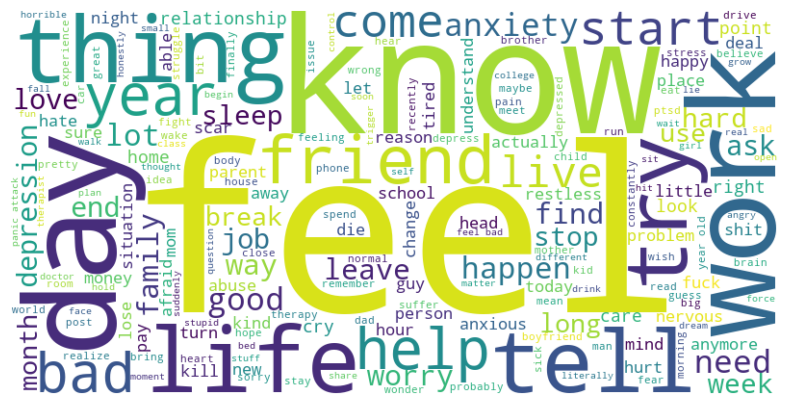

In [180]:
#Visualize the fully preprocessed data
#Select the column to be turned into a word cloud from data_reduced

#Create Word Cloud for the "NoStopWords" column of the dataframew
#This column is the fully preprocessed version of the original data
text_data = ' '.join(data_reduced['ContentWords'].fillna('').astype(str).tolist())

#Define additional stop words as necessary to remove from the word cloud
stopwords = set(STOPWORDS)
#Custom Stopwords (remove as necessary to become more familiar with relevant, high-value data)
stopwords.update(["get", "want", "talk", "student", "students", "professor", "people", "classes", "others","think","time"])

#Generate the word cloud
wordcloud = WordCloud(
    width=800,
    height=400,
    background_color='white',
    stopwords = stopwords,
    normalize_plurals=False,    #otherwise "nervous" is drawn as "nervou"
    min_font_size=10
).generate(text_data)

#Display the generated image using matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off") # Hide the axis ticks
plt.savefig ('WordCloud.png')
plt.show()

In [174]:
#Download the Word Cloud (optional)
#Use the same filename as was used in plot.savefig in the previous cell
try:
    from google.colab import files
    files.download('WordCloud.png')
except ImportError:
    print('Not running in Colab - the image is already saved next to this notebook')

# Data Visualization (Bar Charts)

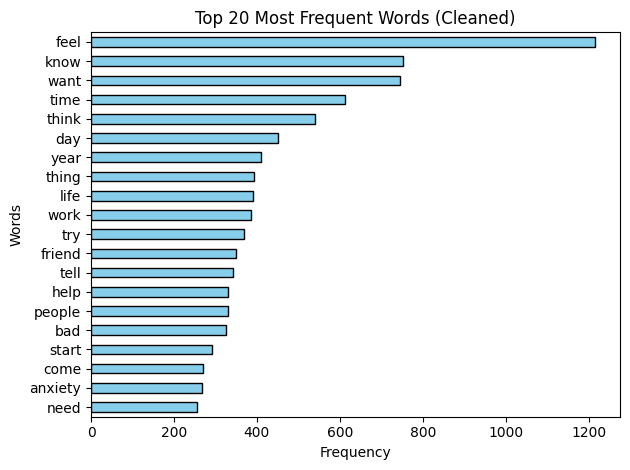

In [175]:
import pandas as pd
import matplotlib.pyplot as plt

#Tokenize words, count frequencies, and grab the top 10 most common words
#Adjust "10" in the code below to accommodate more or fewer top words
word_counts = (
    data_reduced['ContentWords']
    .str.lower()
    .str.split()
    .explode()
    .value_counts()
    .head(20)
)

#Plot a horizontal bar chart (inverted so the highest frequency is at the top)
word_counts.sort_values(ascending=True).plot.barh(color='skyblue', edgecolor='black')

#Customize and display the chart
plt.title('Top 20 Most Frequent Words (Cleaned)')
plt.xlabel('Frequency')
plt.ylabel('Words')
plt.tight_layout()
plt.savefig ('BarChart.png')
plt.show()


In [176]:
#Download the BarChart (optional)
#Use the same filename as was used in plot.savefig in the previous cell
try:
    from google.colab import files
    files.download('BarChart.png')
except ImportError:
    print('Not running in Colab - the image is already saved next to this notebook')

# Data Visualization by Theme (Word Clouds)

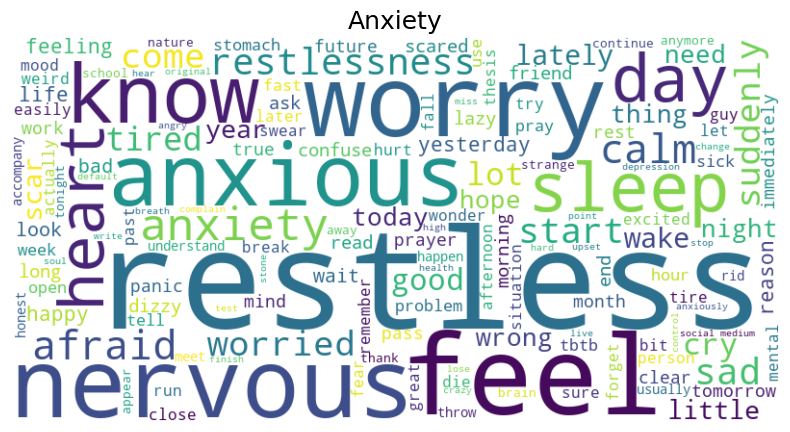

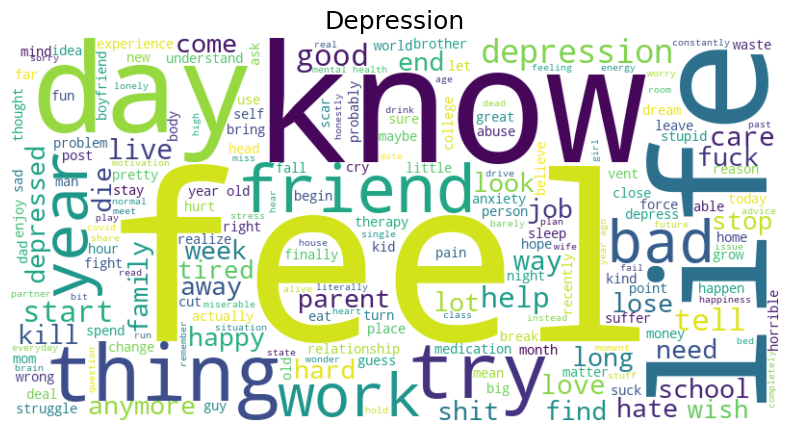

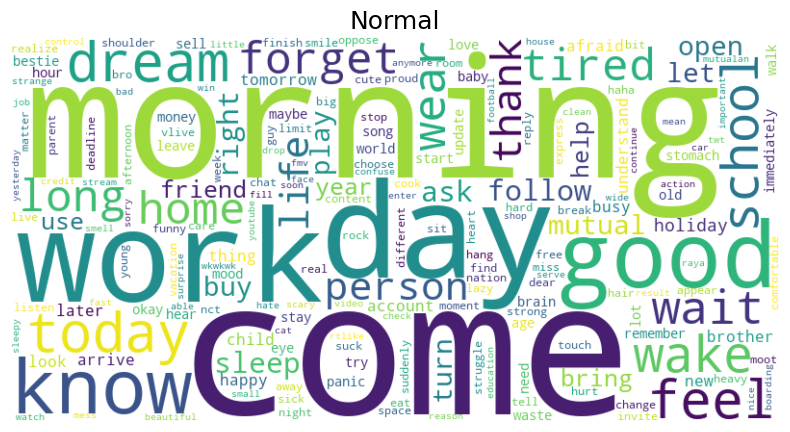

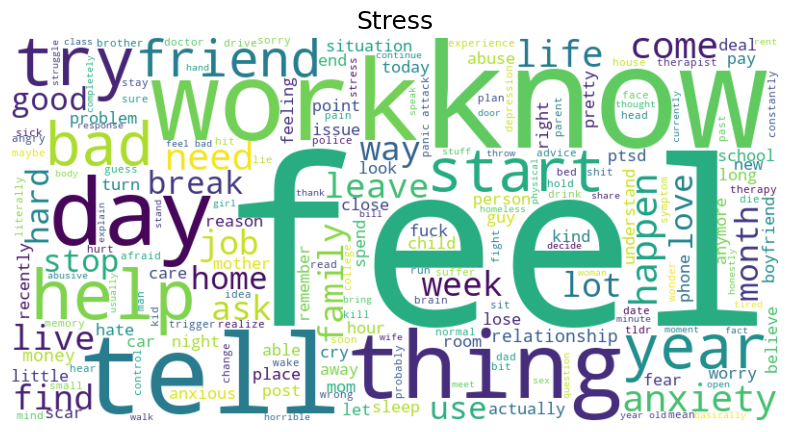

In [177]:
#Word clouds for each of the four themes, one at a time
#The data is already labelled, so each cloud is simply the "ContentWords" (the
#cleaned and fully preprocessed responses) of one AssignedTheme, drawn with the
#same settings and stopwords as the word cloud for the whole dataset above.
#Each theme gets its own figure and its own image file.
for theme in themes:
    segment = data_reduced.loc[data_reduced['AssignedTheme'] == theme, 'ContentWords']
    theme_text = ' '.join(segment.fillna('').astype(str).tolist())

    theme_cloud = WordCloud(
        width=800,
        height=400,
        background_color='white',
        stopwords = stopwords,
        normalize_plurals=False,    #otherwise "nervous" is drawn as "nervou"
        min_font_size=10
    ).generate(theme_text)

    plt.figure(figsize=(10, 5))
    plt.imshow(theme_cloud, interpolation='bilinear')
    plt.title(theme, fontsize=18)    #label the cloud with its theme
    plt.axis("off") # Hide the axis ticks
    plt.savefig (f'WordCloud_{theme}.png')
    plt.show()

# Data Visualization by Theme (Bar Charts)

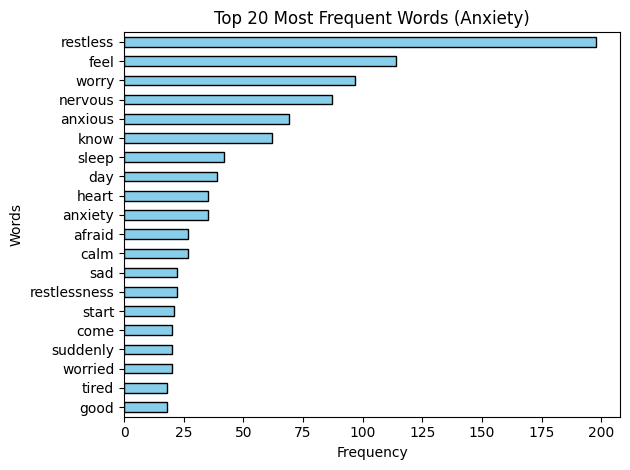

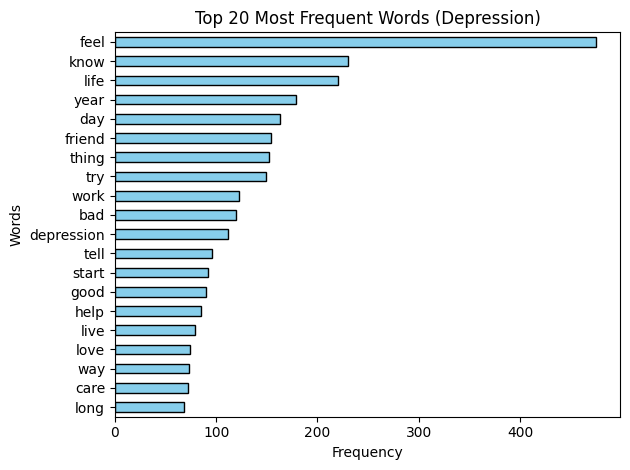

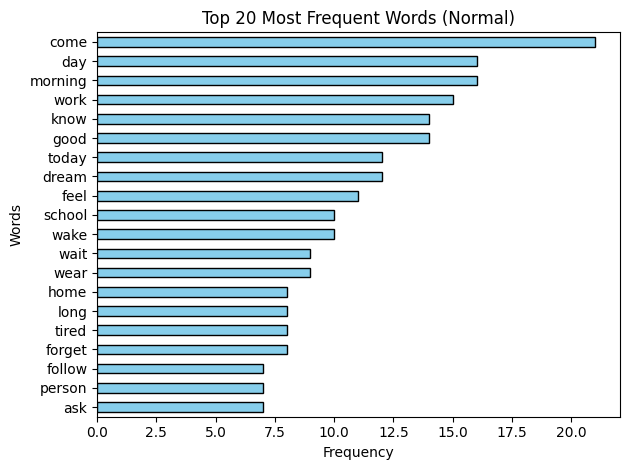

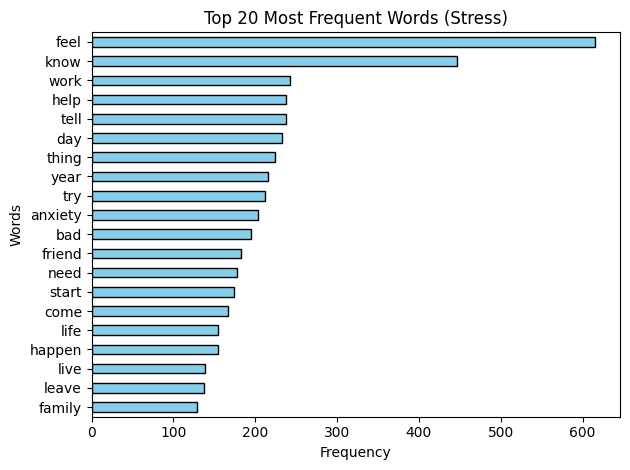

In [178]:
#Bar charts for each of the four themes, one at a time
#Top 20 words per theme, drawn the same way as the bar chart for the whole
#dataset above.  The words come from the same "ContentWords" and have the same
#stopwords removed as the theme word clouds, so the two can be compared.
#Each theme gets its own figure and its own image file.
for theme in themes:
    segment = data_reduced.loc[data_reduced['AssignedTheme'] == theme, 'ContentWords']
    words = segment.str.lower().str.split().explode().dropna()
    theme_counts = words[~words.isin(stopwords)].value_counts().head(20)

    #Plot a horizontal bar chart (inverted so the highest frequency is at the top)
    plt.figure()
    theme_counts.sort_values(ascending=True).plot.barh(color='skyblue', edgecolor='black')

    #Customize and display the chart
    plt.title(f'Top 20 Most Frequent Words ({theme})')
    plt.xlabel('Frequency')
    plt.ylabel('Words')
    plt.tight_layout()
    plt.savefig (f'BarChart_{theme}.png')
    plt.show()